# Filtros lineares e não lineares em imagens

Vamos aplicar quatro filtros à imagem de moedas do scikit-image. Em cada um, uma janela percorre a imagem e determina o novo valor do pixel central. Compare, em especial, os contornos claros das moedas e os pequenos detalhes em seu interior.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

original = data.coins()

## 1. Convolução manual e filtro da média

Nas bordas, repetimos a intensidade do pixel mais próximo. Assim cada janela fica completa, inclusive nos cantos, e a saída tem as mesmas dimensões da entrada.

Na convolução, giramos o núcleo em 180°, multiplicamos cada valor da janela pelo peso correspondente e somamos os produtos. Para a média em uma janela de lado $k$, todos os pesos valem $1/k^2$.

In [ ]:
def validar_tamanho(tamanho):
    if not isinstance(tamanho, (int, np.integer)) or tamanho < 1 or tamanho % 2 == 0:
        raise ValueError("O tamanho da janela deve ser um inteiro positivo e ímpar.")


def convolucao_manual(imagem, nucleo):
    imagem = np.asarray(imagem, dtype=float)
    nucleo = np.asarray(nucleo, dtype=float)
    if imagem.ndim != 2 or imagem.size == 0 or nucleo.ndim != 2:
        raise ValueError("Use uma imagem em cinza não vazia e um núcleo bidimensional.")

    altura, largura = nucleo.shape
    validar_tamanho(altura)
    validar_tamanho(largura)
    bordas = ((altura // 2, altura // 2), (largura // 2, largura // 2))
    estendida = np.pad(imagem, bordas, mode="edge")
    pesos = nucleo[::-1, ::-1]
    saida = np.empty_like(imagem)

    for linha, coluna in np.ndindex(imagem.shape):
        soma = 0.0
        for i in range(altura):
            for j in range(largura):
                soma += estendida[linha + i, coluna + j] * pesos[i, j]
        saida[linha, coluna] = soma
    return saida


def filtro_media(imagem, tamanho=3):
    validar_tamanho(tamanho)
    nucleo = np.full((tamanho, tamanho), 1.0 / tamanho**2)
    return convolucao_manual(imagem, nucleo)

## 2. Filtros de mediana, moda e máxima

Os três filtros percorrem as mesmas janelas. A **mediana** ordena as intensidades e escolhe a central. A **moda** conta as ocorrências de cada intensidade e escolhe a mais frequente. Em caso de empate, usamos a menor intensidade entre as empatadas. A **máxima** escolhe o pixel mais claro.

In [ ]:
def aplicar_em_janelas(imagem, tamanho, operacao):
    validar_tamanho(tamanho)
    imagem = np.asarray(imagem)
    if imagem.ndim != 2 or imagem.size == 0:
        raise ValueError("Use uma imagem em escala de cinza não vazia.")

    estendida = np.pad(imagem, tamanho // 2, mode="edge")
    saida = np.empty_like(imagem)
    for linha, coluna in np.ndindex(imagem.shape):
        janela = estendida[linha:linha + tamanho, coluna:coluna + tamanho]
        saida[linha, coluna] = operacao(janela)
    return saida


def filtro_mediana(imagem, tamanho=3):
    def mediana(janela):
        ordenados = sorted(janela.flat)
        return ordenados[len(ordenados) // 2]

    return aplicar_em_janelas(imagem, tamanho, mediana)


def filtro_moda(imagem, tamanho=3):
    def moda(janela):
        contagens = {}
        for valor in janela.flat:
            contagens[valor] = contagens.get(valor, 0) + 1
        maior_contagem = max(contagens.values())
        return min(valor for valor, total in contagens.items() if total == maior_contagem)

    return aplicar_em_janelas(imagem, tamanho, moda)


def filtro_maxima(imagem, tamanho=3):
    return aplicar_em_janelas(imagem, tamanho, lambda janela: max(janela.flat))

## 3. Conferência com uma janela conhecida

Na matriz abaixo, o pixel central enxerga os nove valores. Sua vizinhança soma 42, tem mediana 4 e máxima 9. Os valores 2 e 8 aparecem duas vezes cada, então a regra de desempate dá moda 2.

In [ ]:
amostra = np.array([[2, 8, 1],
                    [8, 9, 2],
                    [3, 4, 5]], dtype=np.uint8)

assert np.isclose(filtro_media(amostra)[1, 1], 42 / 9)
assert filtro_mediana(amostra)[1, 1] == 4
assert filtro_moda(amostra)[1, 1] == 2
assert filtro_maxima(amostra)[1, 1] == 9
assert convolucao_manual(amostra, [[1, 0, 0]])[1, 1] == 2

## 4. Original e resultado de cada filtro

Cada linha compara a imagem original com o resultado de um filtro. Usamos a mesma escala de cinza (0 a 255) nos oito painéis.

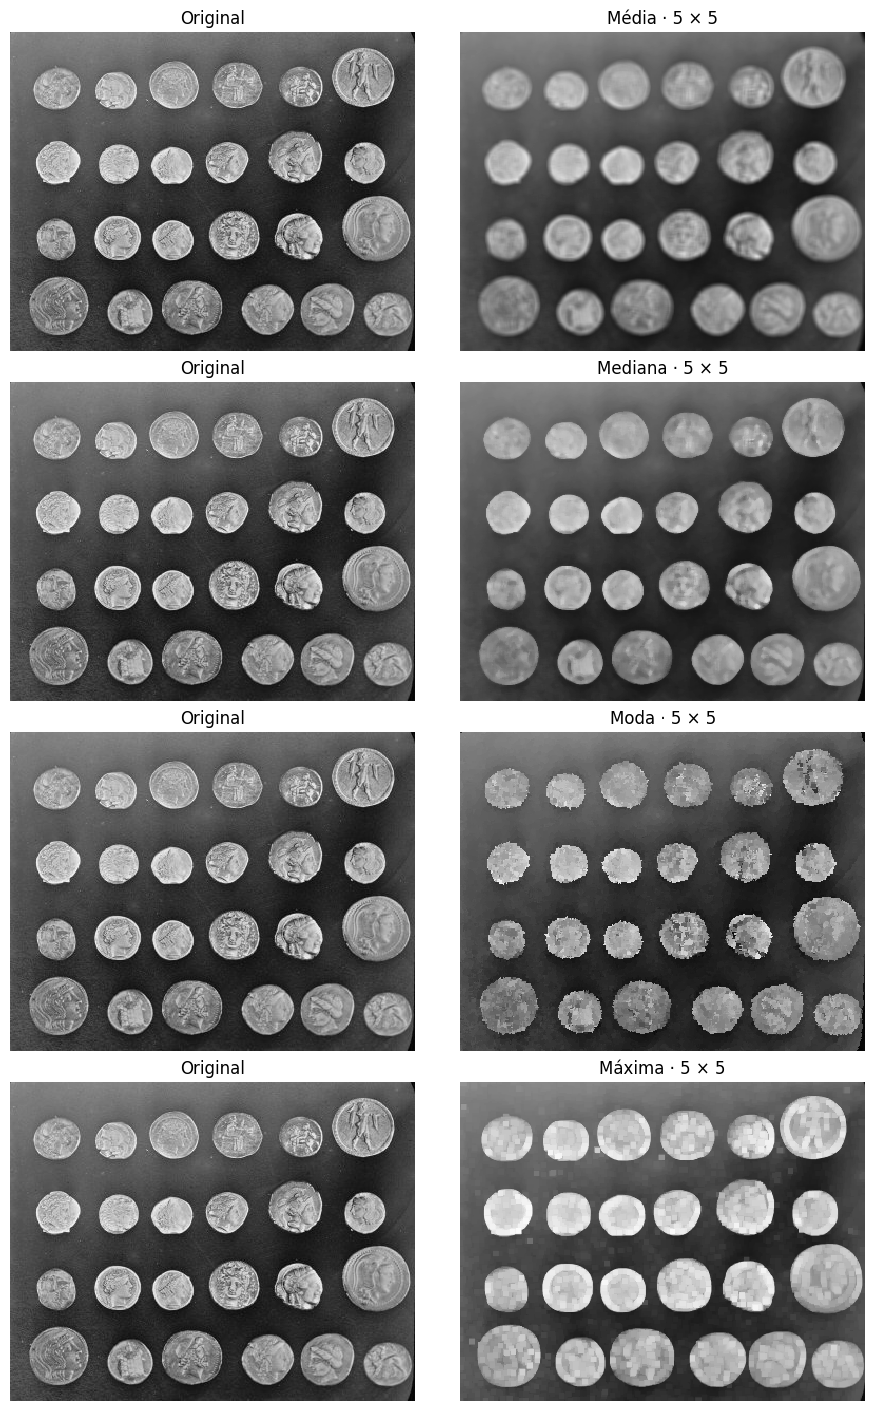

In [ ]:
tamanho = 5
filtros = [
    ("Média", filtro_media),
    ("Mediana", filtro_mediana),
    ("Moda", filtro_moda),
    ("Máxima", filtro_maxima),
]

figura, eixos = plt.subplots(len(filtros), 2, figsize=(9, 14), layout="constrained")
for (nome, filtro), (esquerda, direita) in zip(filtros, eixos):
    filtrada = filtro(original, tamanho)
    for eixo, imagem, titulo in [
        (esquerda, original, "Original"),
        (direita, filtrada, f"{nome} · {tamanho} × {tamanho}"),
    ]:
        eixo.imshow(imagem, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        eixo.set_title(titulo)
        eixo.axis("off")
plt.show()

média: suaviza tanto a textura quanto os contornos das moedas, pois mistura intensidades vizinhas.

mediana: suaviza detalhes pequenos e conserva melhor a transição entre a moeda e o fundo.

moda: janelas com muitos tons diferentes podem produzir manchas, especialmente quando há empates.

máxima: os reflexos e as bordas claras se alargam porque um único pixel claro pode determinar a saída de várias janelas vizinhas.